# check_export (dask)

Reduced statistics of the A1 dataset, computed **lazily with dask** so the full
(3001, 5, 128, 129, 128) field is never loaded into RAM.

Quantities (all reductions — no full field kept):
1. Mean velocity profile along y           → (3, 129)
2. Mean & std of velocity over time        → (3, 128, 129, 128)   [for train/test uniformity]
3. Stationarity over time (d⟨u⟩/dt)        → (3, 129) per snapshot → profile
4. Friction Re over time                   → (N,)
5. Divergence through time (mean div u)    → (N,)

Dask handles parallelism (64 threads) and memory; we just declare the reductions.

In [1]:
import zarr
import s3fs
import numpy as np
import dask
import dask.array as da
from dask import delayed
import matplotlib.pyplot as plt
from tqdm.dask import TqdmCallback


In [2]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import trackio
from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn

keys = 'u', 'v', 'w', 'p_total'

def extract(real, keys):
    with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
        data = []
        for k in keys:
            data.append(np.array(f[real][k]))
        return np.stack(data, axis=1)

realizations = ['R13', 'R14', 'R15', 'R18', 'R19', 'R21', 'R22', 'R23', 'R26', 'R28', 'R3', 'R4', 'R5']
samplings = {real: np.s_[:-1:5000 // 300] if real in ["R3", "R4", "R5"] else np.s_[:] for real in realizations} 

raw_d = {real: extract(real, keys)[samplings[real]] for real in realizations}
all_data = np.concatenate(list(raw_d.values()), axis=0)
T, C, X, Y, Z = all_data.shape

# Test and val realizations choosen as they have roughly avg mean
val_realizations = ["R18", "R5"]
test_realizations = ["R3", "R14"]  # ONLY USE FOR FINAL BENCHMARK, ANY DECISION TAKEN AFTER PERFORMANCE IS ESTABLISHED ON THIS DS IS LEAKAGE
train_realizations = [real for real in realizations if real not in val_realizations + test_realizations]
val_npds = np.concatenate([raw_d[r] for r in val_realizations])
train_npds = np.concatenate([raw_d[r] for r in train_realizations])
u = train_npds[:, :3, :, :, :]


def domain():
    data = {}
    keys = ['x', 'y', 'z']
    with h5py.File("/data1/dataToYouri/couette_dns_ml_f32.h5", 'r') as f:
        for k in keys:
            data[k] = np.array(f[k])
        return data

domain = domain()


In [3]:
y = domain["y"]

In [4]:
print(f"{u.nbytes / 1024**3:.2f} GiB")

0.57 GiB


## 1. Mean velocity profile along y

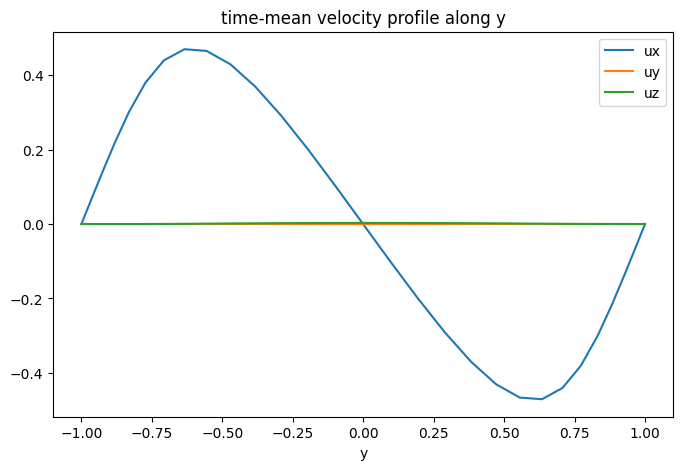

(3, 33)

In [5]:
with TqdmCallback(desc="u mean"):
    u_mean_y = u.mean(axis=(0, 2, 4))      # (3, 129)
plt.figure(figsize=(8, 5))
for c, lab in enumerate(['ux', 'uy', 'uz']):
    plt.plot(y, u_mean_y[c], label=lab)
plt.title('time-mean velocity profile along y'); plt.xlabel('y'); plt.legend(); plt.show()
u_mean_y.shape

## 2. Mean & std of velocity per sample, per component (for train/test uniformity)

Mean and std over the **spatial** axes (x,y,z) for each snapshot and each velocity component
giving `(N, 3)`. Lets you check that the per-sample statistics are uniform over time before
splitting train/test.

mean-per-sample: (2700, 3)  std-per-sample: (2700, 3)
ux: mean-of-mean=-0.0003  std-of-mean=0.0112  | mean-of-std=0.3447  std-of-std=0.0187
uy: mean-of-mean=0.0000  std-of-mean=0.0000  | mean-of-std=0.0316  std-of-std=0.0098
uz: mean-of-mean=0.0010  std-of-mean=0.0023  | mean-of-std=0.0535  std-of-std=0.0197


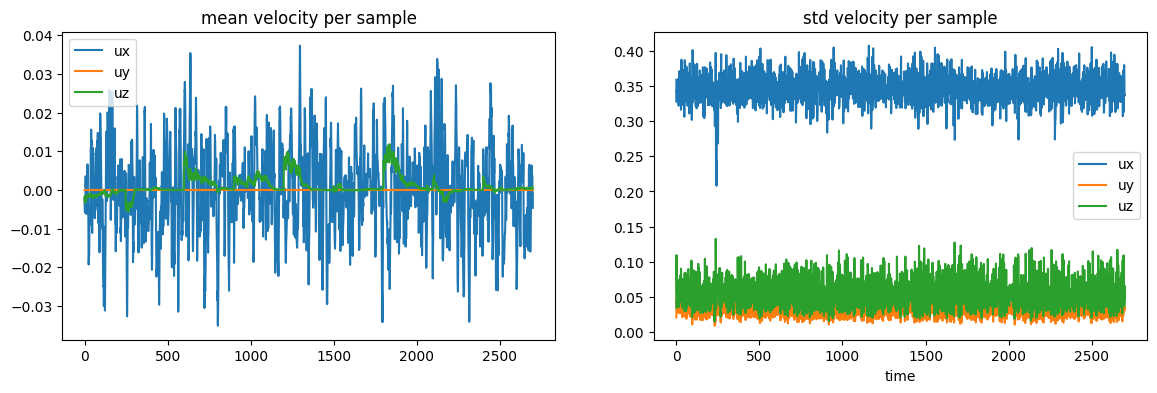

In [6]:
with TqdmCallback(desc='mean-per-sample'):
    u_mean_s = u.mean(axis=(2, 3, 4))      # (N, 3) - mean over x,y,z per snapshot
with TqdmCallback(desc='std-per-sample'):
    u_std_s  = u.std(axis=(2, 3, 4))       # (N, 3) - std over x,y,z per snapshot
print('mean-per-sample:', u_mean_s.shape, ' std-per-sample:', u_std_s.shape)

# uniformity: do the per-sample stats stay flat over time? (per component)
for c, lab in enumerate(['ux', 'uy', 'uz']):
    print(f"{lab}: mean-of-mean={u_mean_s[:, c].mean():.4f}  std-of-mean={u_mean_s[:, c].std():.4f}  "
          f"| mean-of-std={u_std_s[:, c].mean():.4f}  std-of-std={u_std_s[:, c].std():.4f}")

# per-sample mean & std over time (per component)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for c, lab in enumerate(['ux', 'uy', 'uz']):
    ax[0].plot(u_mean_s[:, c], label=lab)
    ax[1].plot(u_std_s[:, c], label=lab)
ax[0].set_title('mean velocity per sample'); ax[0].legend()
ax[1].set_title('std velocity per sample'); ax[1].legend()
plt.xlabel('time'); plt.show()

## 3. Stationarity over time  (d⟨u⟩/dt of the y-profile)

dudt: (2700, 3, 33)


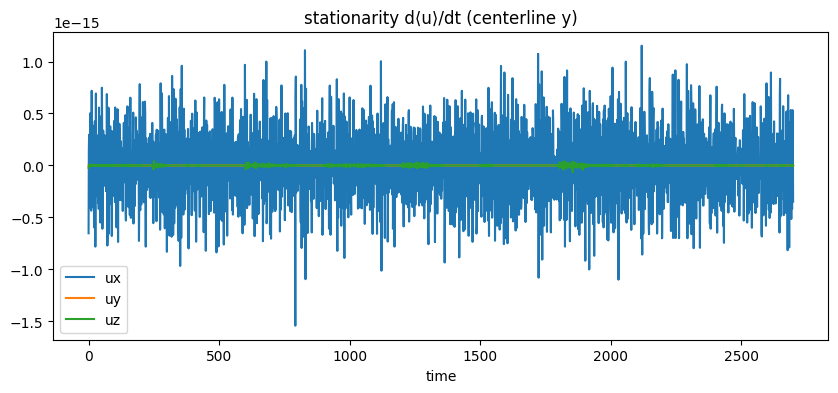

In [7]:
# per-snapshot y-profile (mean over x,z) -> (N, 3, ), then d/dt
with TqdmCallback(desc='u-prof'):
    u_prof = u.mean(axis=(2, 4))           # (N, 3, )
dudt = np.gradient(u_prof, axis=0)               # (N, 3, )
print("dudt:", dudt.shape)
plt.figure(figsize=(10, 4))
for c, lab in enumerate(['ux', 'uy', 'uz']):
    plt.plot(dudt[:, c, 32], label=lab)          # centerline y
plt.title('stationarity d⟨u⟩/dt (centerline y)'); plt.xlabel('time'); plt.legend(); plt.show()

## RMS fluctuations

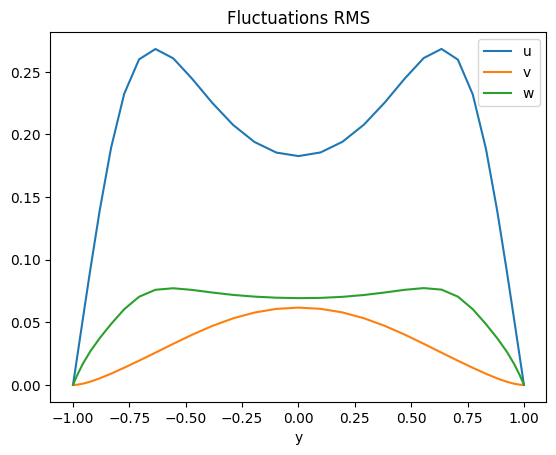

In [8]:
u_fluc = u - u.mean(axis=(0, 2, 4), keepdims=True)
rms = np.sqrt((u_fluc ** 2).mean(axis=(0, 2, 4)))
for l, u_ in zip(["u", "v", "w"], rms[:]):
    plt.plot(y, u_, label=l)

plt.legend()
plt.title("Fluctuations RMS")
plt.xlabel("y")
plt.show()


## Reynold Stress tensor

In [9]:
u_fluc.shape

(2700, 3, 24, 33, 24)

In [10]:
(u_fluc[:, 0] * u_fluc[:, 1]).shape

(2700, 24, 33, 24)

In [11]:
R_stress = np.einsum("ti...,tj...->tij...", u_fluc, u_fluc).mean(axis=(0, 3, 5))

In [12]:
R_stress.shape

(3, 3, 33)

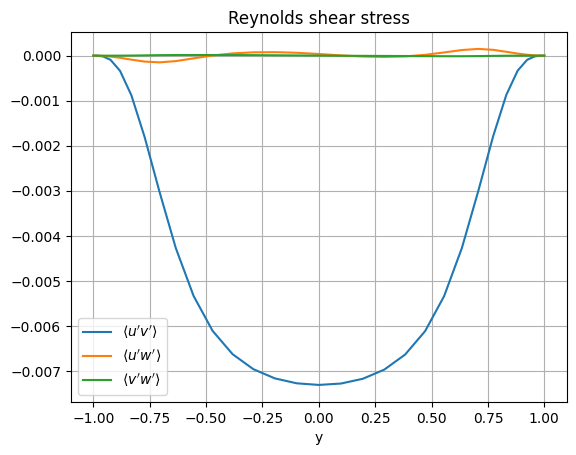

In [13]:
plt.plot(y, R_stress[0, 1], label=r"$\langle u'v'\rangle$")
plt.plot(y, R_stress[0, 2], label=r"$\langle u'w'\rangle$")
plt.plot(y, R_stress[1, 2], label=r"$\langle v'w'\rangle$")
plt.title("Reynolds shear stress")
plt.legend()

plt.xlabel("y")
plt.grid(True)

plt.show()

## Energy spectra

In [14]:
u.shape

(2700, 3, 24, 33, 24)

In [39]:
T, C, X, Y, Z = u_fluc.shape
xzfft = np.fft.fftn(u_fluc, axes=(2, 4))
power = (np.abs(xzfft) ** 2).mean(axis=(0)) / (X * Z)**2
power = np.fft.fftshift(power, axes=(1, 3))

In [37]:
xzfft.shape

(3, 24, 33, 24)

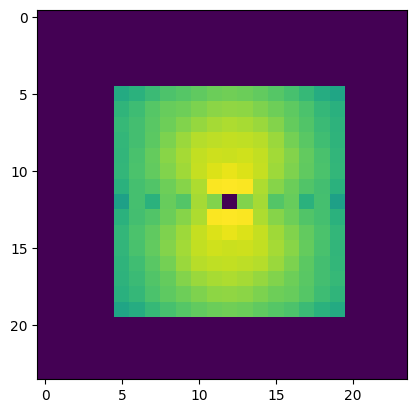

In [48]:
plt.imshow(np.log10(power[1, :, 5, :] + 1e-16))
plt.show()

/tmp/ipykernel_919212/22362068.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


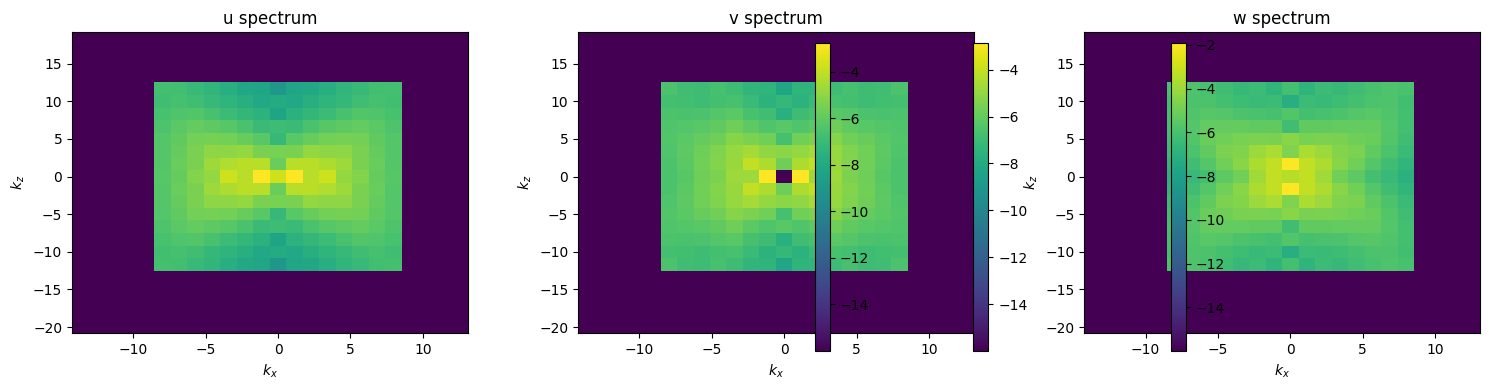

In [45]:
dx = domain["x"][1] - domain["x"][0]
dz = domain["z"][1] - domain["z"][0]

kx = np.fft.fftshift(np.fft.fftfreq(X, d=dx)) * 2*np.pi
kz = np.fft.fftshift(np.fft.fftfreq(Z, d=dz)) * 2*np.pi

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

iy = 15  # Selected wall-normal index

for i, name in enumerate(["u", "v", "w"]):
    p = power[i, :, iy, :]

    im = ax[i].pcolormesh(
        kx, kz,
        np.log10(p.T + 1e-16),
        shading="auto"
    )
    ax[i].set_title(f"{name} spectrum")
    ax[i].set_xlabel(r"$k_x$")
    ax[i].set_ylabel(r"$k_z$")
    fig.colorbar(im, ax=ax)

plt.tight_layout()

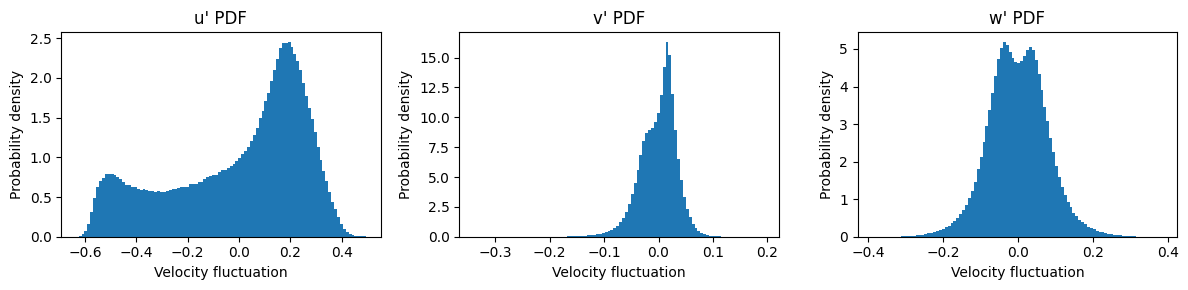

In [51]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

iy = 10

for i, name in enumerate(["u", "v", "w"]):
    values = u_fluc[:, i, :, iy, :].ravel()

    ax[i].hist(values, bins=100, density=True)
    ax[i].set_title(f"{name}' PDF")
    ax[i].set_xlabel("Velocity fluctuation")
    ax[i].set_ylabel("Probability density")

plt.tight_layout()